# Ancilla-mediated fixed-point quantum search

This notebook demonstrates the search method described in *Ancilla-mediated
fixed-point quantum search using Grover iterations* by Yash Prabhat, Snigdha
Thakur and Ankur Raina. It follows Algorithm 1 and Appendix A of the manuscript
version dated November 7, 2026.

We prepare a superposition of candidates, amplify it, and check a flag qubit.
If the flag is 1, we have found a solution and stop. If it is 0, we keep the
remaining state and try the next round. We do not prepare a fresh uniform
state after a failed check.

Install the dependencies, edit **Your experiment**, then choose **Restart Kernel
and Run All**. This notebook contains all the search functions it needs.
The saved outputs show the default 10-qubit experiment. Rerun every cell after
changing the settings so the tables and figures match your choices.

[Repository and setup instructions](https://github.com/dubeyPraY/Fixed-Point-Search)
| [Companion guide](https://github.com/dubeyPraY/Fixed-Point-Search/blob/main/Codes/companion.pdf)


## 1. Dependencies

Use **Python 3.10 or newer** in a fresh environment if possible.

| Package | Why we need it |
|---|---|
| `qiskit>=2.6,<3` | Quantum circuits and statevectors |
| `numpy>=2,<3` | Work with the amplitudes and sample outcomes |
| `matplotlib>=3.9,<3.11` | Plot the results and draw circuits |
| `pylatexenc>=2.10,<3` | Support Qiskit's graphical circuit labels |
| `ipython>=8` | Display tables, text, and figures in the notebook |
| `ipykernel>=6` | Run the Python notebook kernel |

Open the file in JupyterLab, Jupyter Notebook, or VS Code with Jupyter support.
For a new local setup, install JupyterLab too: `python -m pip install jupyterlab`.
No IBM account, quantum device, or Qiskit Aer installation is needed.

Uncomment the next line and run it **once** if packages are missing. Restart the
kernel after installing. The notebook prints the versions it actually uses below.

The repository root includes `requirements.txt` with the tested package versions.
Follow the README to create a separate Python environment before opening the notebook.


In [1]:
# Install into the current notebook's Python environment, then restart its kernel.
# %pip install "qiskit>=2.6,<3" "numpy>=2,<3" "matplotlib>=3.9,<3.11" "pylatexenc>=2.10,<3" "ipython>=8" "ipykernel>=6"


In [2]:
import math
import html
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import qiskit
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister, qpy
from qiskit.quantum_info import Statevector
from IPython.display import display, HTML, Markdown

# Keep the figures inside the notebook.
%matplotlib inline

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2,
})
print(f"Python {sys.version.split()[0]} | Qiskit {qiskit.__version__} | "
      f"NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")


Python 3.10.9 | Qiskit 2.6.2 | NumPy 2.2.6 | Matplotlib 3.10.9


## 2. Your experiment

`TOTAL_QUBITS` includes **one flag qubit**. Thus 10 total qubits means 9 data
qubits and 512 candidates. To search 1024 candidates, set it to 11.

Enter solutions as decimal integers or binary strings. Examples:

* One solution: `[37]`
* Several solutions: `[5, 37, 127]`
* No solutions: `[]`
* Binary labels: `["000100101", "001111111"]`
* All candidates, for a small test: `list(range(2 ** (TOTAL_QUBITS - 1)))`

`SHOW_CIRCUIT` is **False by default**. Turn it on to build and display the
search circuit. The compact drawing groups each round into one box; the full
drawing shows its G and F blocks. Both include the measurements and conditions.

The fast engine is recommended for experiments. The `qiskit` engine applies
the gate circuits directly and is useful as an independent check. It can build
internal gate blocks even when circuit display is off.


In [3]:
# Change these settings, then run the remaining cells from top to bottom.
TOTAL_QUBITS = 10         # Includes the flag: 10 total = 9 data + 1 flag.
SOLUTION_STATES = [37]    # Use [] for none, or a list of several solutions.
SHOTS = 10_000            # Number of independent search attempts to sample.
SEED = 12345             # Keep this fixed to reproduce the same sampled results.

SHOW_CIRCUIT = False      # Set True to build and draw the search circuit.
CIRCUIT_DETAIL = "compact"  # "compact" or "full"; full drawings can be large.
ENGINE = "fast"           # "fast" or "qiskit".
SAVE_RESULTS = False      # Set True to save CSV tables and PNG figures.
OUTPUT_FOLDER = Path("notebook_results")


In [4]:
def parse_solutions(values, n_data):
    """Accept decimal integers or binary labels, and catch mistakes early."""
    parsed = []
    for value in values:
        if isinstance(value, str):
            bits = value.strip().lower().removeprefix("0b")
            if not bits or any(bit not in "01" for bit in bits):
                raise ValueError(f"{value!r} is not a binary string.")
            if len(bits) > n_data:
                raise ValueError(f"{value!r} has more than {n_data} data bits.")
            number = int(bits, 2)
        elif isinstance(value, (int, np.integer)) and not isinstance(value, bool):
            number = int(value)
        else:
            raise ValueError("Use integer indices or binary strings for solutions.")
        if not 0 <= number < 2**n_data:
            raise ValueError(f"Solution {number} must be between 0 and {2**n_data - 1}.")
        parsed.append(number)
    return tuple(sorted(set(parsed)))

if isinstance(TOTAL_QUBITS, bool) or not isinstance(TOTAL_QUBITS, int) or TOTAL_QUBITS < 2:
    raise ValueError("Choose at least 2 total qubits: one data qubit and one flag.")
if isinstance(SHOTS, bool) or not isinstance(SHOTS, int) or SHOTS < 1:
    raise ValueError("SHOTS must be a positive integer.")
if ENGINE not in {"fast", "qiskit"}:
    raise ValueError("ENGINE must be 'fast' or 'qiskit'.")
if CIRCUIT_DETAIL not in {"compact", "full"}:
    raise ValueError("CIRCUIT_DETAIL must be 'compact' or 'full'.")

N_DATA = TOTAL_QUBITS - 1
N = 2**N_DATA
MARKED = parse_solutions(SOLUTION_STATES, N_DATA)
M = len(MARKED)  # Used to check the theory; the search schedule does not need it.
print(f"{TOTAL_QUBITS} total qubits = {N_DATA} data + 1 flag")
print(f"Candidates: {N:,} | Marked candidates: {M:,} | Shots: {SHOTS:,}")
print("Marked indices:", MARKED if M <= 20 else f"{MARKED[:20]} ...")
print(f"One full statevector uses {16 * 2**TOTAL_QUBITS / 2**20:.3f} MiB.")
print("The simulation keeps several arrays; memory and runtime grow with the register size.")


10 total qubits = 9 data + 1 flag
Candidates: 512 | Marked candidates: 1 | Shots: 10,000
Marked indices: (37,)
One full statevector uses 0.016 MiB.
The simulation keeps several arrays; memory and runtime grow with the register size.


## 3. What happens in one round?

Write the starting data state as
\[
|u\rangle=\cos\theta\,|R\rangle+\sin\theta\,|S\rangle,
\qquad \theta=\arcsin\sqrt{M/N}.
\]
Here \(|S\rangle\) groups the solution states and \(|R\rangle\) groups the others.
The oracle tells the circuit which states are solutions; the schedule does not
need to know how many there are.

1. **Amplify:** apply G the number of times chosen for this round.
2. **Flag:** F moves the current solution amplitude into flag = 1.
3. **Measure the flag:** a 1 ends the search. A 0 leaves the data state at
   \(\cos(2\theta)|R\rangle+\sin(2\theta)|S\rangle\), up to an overall phase.

The Grover counts are **0, 0, 1, 3, 7, 15, ...**. Each is the number of *new*
Grover operations in that round. Failed rounds reuse their remaining quantum
state instead of preparing a new uniform superposition.

An exhausted schedule means **"not found in this attempt"**. It does not prove
that there are no solutions. This is an ideal, noiseless simulation.


In [5]:
def schedule(n_data: int) -> list[int]:
    """Paper Eq. (22) conservative schedule; independent of the number marked."""
    if n_data < 1:
        raise ValueError("At least one data qubit is required.")
    r = math.ceil(math.log2(math.pi) + n_data / 2)
    return [0] + [(1 << (j - 1)) - 1 for j in range(1, r)]

def checked_marked(n_data: int, marked) -> tuple[int, ...]:
    values = tuple(sorted(set(int(x) for x in marked)))
    if any(x < 0 or x >= 2**n_data for x in values):
        raise ValueError(f"Marked integers must be in [0, {2**n_data - 1}].")
    return values

GROVER_COUNTS = schedule(N_DATA)
QUERY_COUNTS = np.cumsum(np.array(GROVER_COUNTS) + 1)
print("Grover operations in each round:", GROVER_COUNTS)
print("Oracle calls used by each checkpoint:", QUERY_COUNTS.tolist())


Grover operations in each round: [0, 0, 1, 3, 7, 15, 31]
Oracle calls used by each checkpoint: [1, 2, 4, 8, 16, 32, 64]


## 4. The quantum building blocks

The code below defines the same gates as the paper. Defining these functions
does not build the full search circuit yet.

* The oracle changes the sign of each solution state's amplitude.
* G combines that oracle with the usual Grover reflection.
* F first writes the solution flag, then reflects the data **only when the flag is 0**.

The reflection inside F is \(I-2|u\rangle\langle u|\). Its sign matters because
it acts on only one flag branch. We keep it exactly as written in Appendix A.
The explicit list of solutions is a convenient test oracle. For a real problem,
this would be replaced with a reversible circuit that checks your condition.


In [6]:
def all_ones_phase(qc: QuantumCircuit, wires: list[int]) -> None:
    """Change the sign only when all these qubits are 1. No extra qubits are needed."""
    if len(wires) == 1:
        qc.z(wires[0])
    else:
        qc.h(wires[-1])
        qc.mcx(wires[:-1], wires[-1])
        qc.h(wires[-1])

def append_oracle(qc: QuantumCircuit, n_data: int, marked,
                  control: int | None = None) -> None:
    """O = I-2 Pi_S, optionally controlled on flag=1.

    Explicit marked values define a simulation oracle. For a real application,
    replace this with a reversible predicate; the search need not know M.
    """
    for value in marked:
        zero_bits = [q for q in range(n_data) if not (value >> q) & 1]
        for q in zero_bits:
            qc.x(q)
        wires = list(range(n_data))
        if control is not None:
            wires.append(control)
        all_ones_phase(qc, wires)
        for q in zero_bits:
            qc.x(q)

def grover_circuit(n_data: int, marked) -> QuantumCircuit:
    """G=(2|u><u|-I)O, with |u>=H^n|0>."""
    marked = checked_marked(n_data, marked)
    qc = QuantumCircuit(n_data, name="G")
    append_oracle(qc, n_data, marked)
    qc.h(range(n_data))
    qc.x(range(n_data))
    all_ones_phase(qc, list(range(n_data)))
    qc.x(range(n_data))
    qc.h(range(n_data))
    qc.global_phase = math.pi  # Convert I-2|u><u| to 2|u><u|-I.
    return qc

def fixed_point_circuit(n_data: int, marked) -> QuantumCircuit:
    """F = D C_S, exactly Appendix A, including the conditional-reflection sign."""
    marked = checked_marked(n_data, marked)
    a = n_data  # Qiskit MSB: amplitudes [a=0 block, a=1 block].
    qc = QuantumCircuit(n_data + 1, name="F")
    qc.h(a)
    append_oracle(qc, n_data, marked, control=a)
    qc.h(a)
    qc.h(range(n_data))  # P dagger
    qc.x(range(n_data + 1))
    all_ones_phase(qc, list(range(n_data + 1)))
    qc.x(range(n_data + 1))
    qc.h(range(n_data))  # P
    return qc

def dynamic_circuit(n_data: int, marked) -> QuantumCircuit:
    """Executable dynamic circuit: future blocks are skipped after flag=1.

    Classical registers are named flag and data. Only shots with flag=1 are
    successes; a data measurement in a failed shot is not an accepted answer.
    """
    marked = checked_marked(n_data, marked)
    q = QuantumRegister(n_data + 1, "q")
    flag = ClassicalRegister(1, "flag")
    data = ClassicalRegister(n_data, "data")
    qc = QuantumCircuit(q, flag, data)
    qc.h(range(n_data))
    g = grover_circuit(n_data, marked).to_gate()
    f = fixed_point_circuit(n_data, marked).to_gate()
    for count in schedule(n_data):
        with qc.if_test((flag[0], 0)):
            for _ in range(count):
                qc.append(g, list(range(n_data)))
            qc.append(f, list(range(n_data + 1)))
            qc.measure(q[n_data], flag[0])
    qc.measure(q[:n_data], data)
    return qc


## 5. Optional circuit drawing

When drawing is off, this cell skips construction of the full dynamic circuit.
When it is on, `search_circuit` holds the full executable circuit. The compact
view groups the G and F gates of each round without changing their action.

Each round runs only while the last flag result is 0. Once it becomes 1, the
remaining rounds are skipped. The final data measurement is accepted only for
shots with flag = 1. Bit strings read from left to right as `q[n-1] ... q[0]`.


In [7]:
def compact_search_circuit(n_data, marked):
    """Group each real round into one box so the schedule is easier to read."""
    q = QuantumRegister(n_data + 1, "q")
    flag = ClassicalRegister(1, "flag")
    data = ClassicalRegister(n_data, "data")
    circuit = QuantumCircuit(q, flag, data)
    circuit.h(range(n_data))
    g = grover_circuit(n_data, marked).to_gate()
    f = fixed_point_circuit(n_data, marked).to_gate()
    for j, count in enumerate(schedule(n_data)):
        block = QuantumCircuit(n_data + 1)
        for _ in range(count):
            block.append(g, list(range(n_data)))
        block.append(f, list(range(n_data + 1)))
        with circuit.if_test((flag[0], 0)):
            circuit.append(block.to_gate(label=f"Round {j}: {count} G + F"), q)
            circuit.measure(q[n_data], flag[0])
    circuit.measure(q[:n_data], data)
    return circuit

search_circuit = None
if SHOW_CIRCUIT:
    search_circuit = dynamic_circuit(N_DATA, MARKED)
    drawing = (compact_search_circuit(N_DATA, MARKED)
               if CIRCUIT_DETAIL == "compact" else search_circuit)
    display(Markdown(f"**{TOTAL_QUBITS}-qubit search circuit ({CIRCUIT_DETAIL} view)**"))
    circuit_figure = drawing.draw(output="mpl", fold=100, idle_wires=False)
    display(circuit_figure)
    plt.close(circuit_figure)
    print("To inspect F itself, run: fixed_point_circuit(N_DATA, MARKED).draw('mpl')")
else:
    print("Circuit drawing is off. Set SHOW_CIRCUIT = True and rerun to see it.")


Circuit drawing is off. Set SHOW_CIRCUIT = True and rerun to see it.


## 6. Simulate the amplitudes and the measurements

The fast implementation below performs the same operations directly on the
amplitudes. It avoids making large square matrices. The two rows of its working
array hold flag = 0 and flag = 1.

After F, we save the probability of success and the distribution of its answers.
We then keep and normalize only the flag = 0 branch before the next round.
Every shot that reaches a given round has that same remaining state, so we only
need to evolve it once. Later, we sample independent attempts from the saved
branch probabilities. This is equivalent to running the ideal experiment many
times, but avoids repeating the same amplitude calculations.

The `qiskit` option follows the same measurement branches but evolves the actual
gate circuits. Neither engine uses the theoretical success formula to generate
its amplitudes.


In [8]:
def fast_g(state: Statevector, marked: tuple[int, ...]) -> Statevector:
    """Apply Grover's step to each flag branch without a large square matrix."""
    v = state.data.reshape(2, -1).copy()
    v[:, list(marked)] *= -1
    v = 2 * v.mean(axis=1, keepdims=True) - v
    return Statevector(v.reshape(-1))

def fast_f(state: Statevector, marked: tuple[int, ...]) -> Statevector:
    """Write the solution flag, then reflect only the branch where the flag is 0."""
    v = state.data.reshape(2, -1).copy()
    # C_S flips the flag precisely on marked computational-basis states.
    indices = list(marked)
    v[:, indices] = v[::-1, indices].copy()
    # D is I-2|u><u| on a=0, identity on a=1. Do NOT reverse this sign.
    v[0] -= 2 * v[0].mean()
    return Statevector(v.reshape(-1))

def exact_search(n_data=9, marked=(37,), engine="fast") -> dict:
    """Follow the state that continues after each failed check, and save successes.

    This is exact measurement branching, not repeated coherent application of F.
    All shots share the same conditional failure branch, so evolve it only once.
    Neither evolution nor the schedule uses M or theta. Theory uses them only
    afterwards for validation.
    """
    counts = schedule(n_data)
    marked = checked_marked(n_data, marked)
    if engine not in {"fast", "qiskit"}:
        raise ValueError("engine must be 'fast' or 'qiskit'")
    N = 2**n_data
    preparation = QuantumCircuit(n_data + 1)
    preparation.h(range(n_data))
    state = Statevector.from_instruction(preparation)
    if engine == "qiskit":
        g = grover_circuit(n_data, marked)
        f = fixed_point_circuit(n_data, marked)
    survival = 1.0
    oracle_calls = 0
    rows, outcomes = [], []
    expected_calls = 0.0
    for j, count in enumerate(counts):
        if survival == 0:
            break
        expected_calls += survival * (count + 1)
        oracle_calls += count + 1
        for _ in range(count):
            state = (fast_g(state, marked) if engine == "fast" else
                     state.evolve(g, qargs=list(range(n_data))))
        state = fast_f(state, marked) if engine == "fast" else state.evolve(f)
        v = state.data.reshape(2, N)
        p0, p1 = np.sum(np.abs(v)**2, axis=1)
        total = float(p0 + p1)
        if not np.isclose(total, 1, atol=1e-8):
            raise ArithmeticError(f"State lost normalization: {total}")
        conditional = float(p1 / total)
        mass = survival * conditional
        if p1 > 0:
            data_prob = np.abs(v[1])**2 / p1
            outcomes.append((mass, oracle_calls, data_prob))
        survival *= float(p0 / total)
        # Numerically zero branches (e.g. M=N or M=N/2) cannot be normalized.
        if p0 < 1e-25:
            survival = 0.0
        rows.append(dict(check=j, grover_iterations=count,
                         oracle_calls=oracle_calls, conditional_success=conditional,
                         first_success=mass, cumulative_success=1-survival))
        if survival:
            collapsed = np.zeros(2 * N, dtype=complex)
            collapsed[:N] = v[0] / np.sqrt(p0)
            state = Statevector(collapsed)
    return dict(n_data=n_data, marked=marked, rows=rows, outcomes=outcomes,
                success_probability=1-survival, failure_probability=survival,
                expected_oracle_calls=expected_calls,
                max_oracle_calls=sum(g + 1 for g in counts))


In [9]:
result = exact_search(N_DATA, MARKED, engine=ENGINE)
print(f"Simulation complete using the {ENGINE!r} engine.")
print(f"Exact simulated success probability: {result['success_probability']:.10%}")
print(f"Expected oracle calls per attempt: {result['expected_oracle_calls']:.6f}")


Simulation complete using the 'fast' engine.
Exact simulated success probability: 98.9317092682%
Expected oracle calls per attempt: 22.757211


## 7. Calculate the expected results independently

At checkpoint \(j\), the theoretical probability of success, **given that we
reached that checkpoint**, is
\[
p_j=\sin^2(2^j\theta).
\]
The probability of first succeeding there is
\(w_j=p_j\prod_{m<j}(1-p_m)\), and the accumulated success probability is
\[
P_j=1-\prod_{m=0}^{j}(1-p_m).
\]

We count unsuccessful attempts too. If \(Q_{\max}\) is the full schedule cost,
\[
E[Q]=\sum_j 2^j w_j + Q_{\max}P(\text{not found}).
\]
That last term is needed to report the average cost of **all attempts**, rather
than only the successful events. One G or F counts as one oracle query in the
paper's model. This is not the number of elementary hardware gates.


In [10]:
theta = math.asin(math.sqrt(M / N))
n_checks = len(GROVER_COUNTS)
theory_conditional = np.sin((2.0 ** np.arange(n_checks)) * theta) ** 2
theory_first = np.zeros(n_checks)
remaining = 1.0
for j, probability in enumerate(theory_conditional):
    theory_first[j] = remaining * probability
    remaining *= 1 - probability
theory_failure = remaining
theory_cumulative = np.cumsum(theory_first)
theory_expected_queries = float(theory_first @ QUERY_COUNTS + theory_failure * QUERY_COUNTS[-1])

# Some settings guarantee success early. Unreached rounds have zero new successes.
exact_first = np.zeros(n_checks)
exact_conditional = np.full(n_checks, np.nan)
for row in result["rows"]:
    exact_first[row["check"]] = row["first_success"]
    exact_conditional[row["check"]] = row["conditional_success"]
exact_cumulative = np.cumsum(exact_first)

np.testing.assert_allclose(exact_cumulative, theory_cumulative, atol=1e-9)
np.testing.assert_allclose(result["expected_oracle_calls"], theory_expected_queries, atol=1e-9)
print(f"Largest theory vs statevector difference: {np.max(np.abs(exact_cumulative-theory_cumulative)):.3e}")


Largest theory vs statevector difference: 2.776e-16


## 8. Sample repeated search attempts

Each attempt either stops at one checkpoint or finishes without finding a
solution. We sample those stopping events first, then sample the data result
for each successful event. This gives one consistent set of shots for all the
tables and figures below. Changing `SEED` changes the sampled results.


In [11]:
rng = np.random.default_rng(SEED)
event_probabilities = np.append(exact_first, result["failure_probability"])
event_probabilities /= event_probabilities.sum()
event_counts = rng.multinomial(SHOTS, event_probabilities)
first_success_counts = event_counts[:-1]
failed_count = int(event_counts[-1])
success_count = SHOTS - failed_count
sampled_cumulative = np.cumsum(first_success_counts) / SHOTS
sampled_query_mean = float(event_counts @ np.append(QUERY_COUNTS, QUERY_COUNTS[-1]) / SHOTS)

accepted_counts = Counter()
branches_by_cost = {cost: probabilities for _, cost, probabilities in result["outcomes"]}
for j, count in enumerate(first_success_counts):
    if count == 0:
        continue
    probabilities = branches_by_cost[int(QUERY_COUNTS[j])]
    data_counts = rng.multinomial(int(count), probabilities / probabilities.sum())
    for value in np.flatnonzero(data_counts):
        accepted_counts[int(value)] += int(data_counts[value])

assert sum(accepted_counts.values()) == success_count
assert all(value in MARKED for value in accepted_counts)

def wilson_interval(successes, trials, z=1.96):
    """A 95% interval for a sampled proportion, also useful at 0 or 100% success."""
    fraction = np.asarray(successes, dtype=float) / trials
    scale = 1 + z*z/trials
    center = (fraction + z*z/(2*trials)) / scale
    half_width = z*np.sqrt(fraction*(1-fraction)/trials + z*z/(4*trials*trials))/scale
    return np.clip(center-half_width, 0, 1), np.clip(center+half_width, 0, 1)

low, high = wilson_interval(success_count, SHOTS)
print(f"Found a solution: {success_count:,} / {SHOTS:,}")
print(f"Not found: {failed_count:,} / {SHOTS:,}")
print(f"Sampled success rate: {success_count/SHOTS:.4%} (95% interval: {low:.4%} to {high:.4%})")


Found a solution: 9,868 / 10,000
Not found: 132 / 10,000
Sampled success rate: 98.6800% (95% interval: 98.4369% to 98.8857%)


## 9. Expected vs obtained: numbers

**Theory** is calculated from the paper's formula. **Exact simulation** comes
from the evolved statevector and its measurement branches. **Sampled** means the
results of the finite number of attempts you requested. The first two should
agree to rounding precision; the sampled values naturally fluctuate.

Expected counts can be fractional because they are averages over repeated
experiments. A blank conditional probability means the simulator stopped early
because no failure branch remained.


In [12]:
def show_table(headers, rows):
    """Display a small readable table without needing pandas."""
    header = "".join(f"<th style='padding:8px;text-align:left'>{html.escape(str(x))}</th>" for x in headers)
    body = "".join("<tr>" + "".join(
        f"<td style='padding:7px 10px;border-bottom:1px solid #ddd'>{html.escape(str(x))}</td>"
        for x in row) + "</tr>" for row in rows)
    display(HTML(f"<table style='border-collapse:collapse'><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))

summary_headers = ["Quantity", "Theory", "Exact simulation", "Sampled"]
summary_rows = [
    ["Success probability", f"{1-theory_failure:.8f}", f"{result['success_probability']:.8f}", f"{success_count/SHOTS:.8f}"],
    ["Not-found probability", f"{theory_failure:.8f}", f"{result['failure_probability']:.8f}", f"{failed_count/SHOTS:.8f}"],
    ["Successful attempts", f"{SHOTS*(1-theory_failure):.2f}", f"{SHOTS*result['success_probability']:.2f}", str(success_count)],
    ["Oracle calls per attempt", f"{theory_expected_queries:.6f}", f"{result['expected_oracle_calls']:.6f}", f"{sampled_query_mean:.6f}"],
]
show_table(summary_headers, summary_rows)

checkpoint_headers = ["Check j", "New G", "Queries so far", "Conditional P (exact)",
                      "Cumulative P (theory)", "Cumulative P (exact)", "Cumulative P (sampled)", "First successes"]
checkpoint_rows = []
for j in range(n_checks):
    checkpoint_rows.append([j, GROVER_COUNTS[j], int(QUERY_COUNTS[j]),
        "—" if np.isnan(exact_conditional[j]) else f"{exact_conditional[j]:.6f}",
        f"{theory_cumulative[j]:.6f}", f"{exact_cumulative[j]:.6f}",
        f"{sampled_cumulative[j]:.6f}", int(first_success_counts[j])])
display(Markdown("**Checkpoint comparison**"))
show_table(checkpoint_headers, checkpoint_rows)


Quantity,Theory,Exact simulation,Sampled
Success probability,0.98931709,0.98931709,0.98680000
Not-found probability,0.01068291,0.01068291,0.01320000
Successful attempts,9893.17,9893.17,9868
Oracle calls per attempt,22.757211,22.757211,22.987400


**Checkpoint comparison**

Check j,New G,Queries so far,Conditional P (exact),Cumulative P (theory),Cumulative P (exact),Cumulative P (sampled),First successes
0,0,1,0.001953,0.001953,0.001953,0.001600,16
1,0,2,0.007797,0.009735,0.009735,0.009100,75
2,1,4,0.030946,0.040380,0.040380,0.036600,275
3,3,8,0.119953,0.155489,0.155489,0.151200,1146
4,7,16,0.422256,0.512088,0.512088,0.505500,3543
5,15,32,0.975823,0.988204,0.988204,0.985900,4804
6,31,64,0.094369,0.989317,0.989317,0.986800,9


## 10. Expected vs obtained: figures

The first figure compares cumulative success, the stopping checkpoint, and
the oracle-query cost. Error bars on sampled success are **pointwise 95% Wilson
intervals**; checkpoint estimates share the same shots, so they are correlated.
These intervals can miss the theoretical value for some seeds; 95% is not a
guarantee for every individual run.
The mean-cost error bar is about two theoretical standard errors for the
sample mean, not a bound on an individual attempt.

Only the accumulated probability is monotone. The chance of success at one
particular checkpoint can rise or fall.


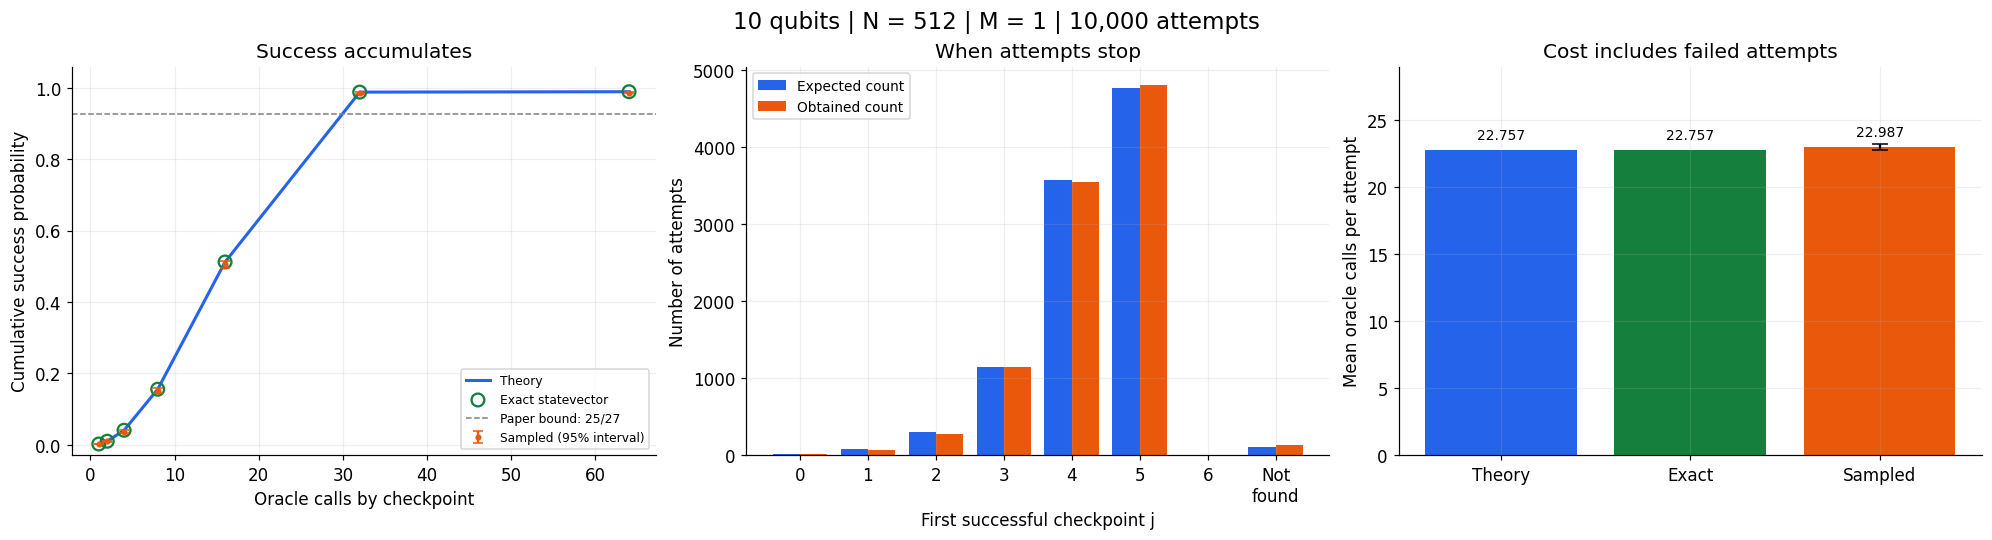

In [13]:
blue, orange, green = "#2563eb", "#ea580c", "#15803d"
figures = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
j_values = np.arange(n_checks)
lower, upper = wilson_interval(np.cumsum(first_success_counts), SHOTS)

ax = axes[0]
ax.plot(QUERY_COUNTS, theory_cumulative, color=blue, lw=2, label="Theory")
ax.scatter(QUERY_COUNTS, exact_cumulative, facecolors="none", edgecolors=green,
           s=70, linewidths=1.5, label="Exact statevector", zorder=4)
ax.errorbar(QUERY_COUNTS, sampled_cumulative,
            yerr=[np.maximum(0, sampled_cumulative-lower), np.maximum(0, upper-sampled_cumulative)],
            fmt=".", color=orange, capsize=3, label="Sampled (95% interval)", zorder=5)
if M:
    ax.axhline(25/27, color="gray", ls="--", lw=1, label="Paper bound: 25/27")
ax.set(xlabel="Oracle calls by checkpoint", ylabel="Cumulative success probability",
       title="Success accumulates", ylim=(-0.03, 1.06))
ax.legend(fontsize=8, loc="best")

ax = axes[1]
event_labels = [str(j) for j in j_values] + ["Not\nfound"]
x = np.arange(n_checks+1)
theory_events = np.append(theory_first, theory_failure)
ax.bar(x-.2, SHOTS*theory_events, width=.4, color=blue, label="Expected count")
ax.bar(x+.2, event_counts, width=.4, color=orange, label="Obtained count")
ax.set_xticks(x, event_labels)
ax.set(xlabel="First successful checkpoint j", ylabel="Number of attempts",
       title="When attempts stop")
ax.legend(fontsize=9)

ax = axes[2]
event_costs = np.append(QUERY_COUNTS, QUERY_COUNTS[-1])
query_variance = float(theory_events @ (event_costs-theory_expected_queries)**2)
query_se = math.sqrt(max(0, query_variance)/SHOTS)
bars = ax.bar(["Theory", "Exact", "Sampled"],
              [theory_expected_queries, result["expected_oracle_calls"], sampled_query_mean],
              color=[blue, green, orange])
ax.errorbar(2, sampled_query_mean, yerr=1.96*query_se, fmt="none", color="black", capsize=5)
ax.bar_label(bars, fmt="%.3f", padding=5, fontsize=9)
ax.set(ylabel="Mean oracle calls per attempt", title="Cost includes failed attempts")
ax.set_ylim(0, max(theory_expected_queries, sampled_query_mean+1.96*query_se)*1.25)
fig.suptitle(f"{TOTAL_QUBITS} qubits | N = {N:,} | M = {M:,} | {SHOTS:,} attempts", fontsize=15)
figures["comparison"] = fig
display(fig)
plt.close(fig)


### Which solutions were returned?

With uniform state preparation, each marked state has the same expected
probability of being returned. The chart compares **unconditional counts per
search attempt**, so it includes a "Not found" bar. With no solutions, that is
the only possible outcome. For more than 16 solutions, the remaining states are
grouped into one labeled bar; no counts are dropped.


Decimal state,Binary state,Expected count,Obtained count
37,000100101,9893.171,9868
Not found,—,106.829,132


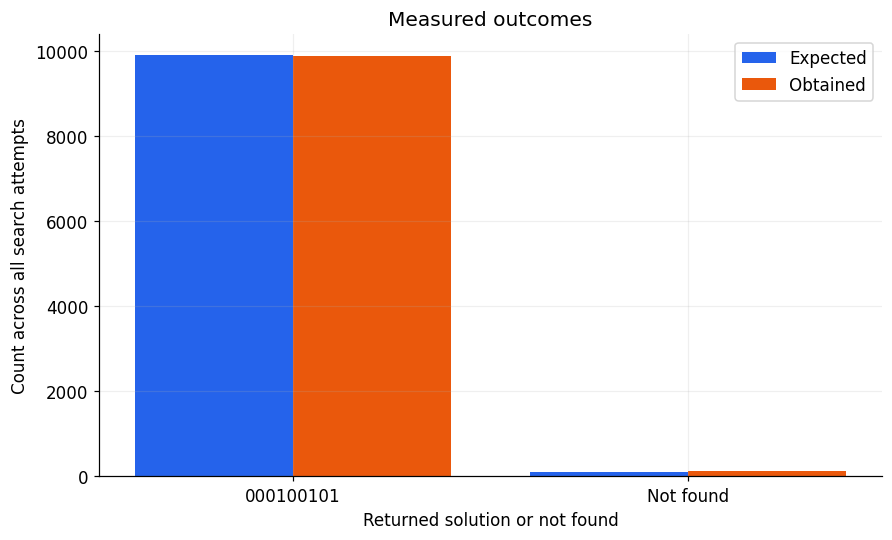

In [14]:
visible_states = list(MARKED[:16])
labels = [format(x, f"0{N_DATA}b") for x in visible_states]
expected_counts = [SHOTS*(1-theory_failure)/M for _ in visible_states] if M else []
obtained_counts = [accepted_counts[x] for x in visible_states]
outcome_rows = [[x, format(x, f"0{N_DATA}b"), f"{expected:.3f}", observed]
                for x, expected, observed in zip(visible_states, expected_counts, obtained_counts)]
if M > len(visible_states):
    other_expected = SHOTS*(1-theory_failure)*(M-len(visible_states))/M
    other_obtained = success_count-sum(obtained_counts)
    labels.append(f"Other {M-len(visible_states)} marked")
    expected_counts.append(other_expected)
    obtained_counts.append(other_obtained)
    outcome_rows.append(["Other marked", "grouped", f"{other_expected:.3f}", other_obtained])
labels.append("Not found")
expected_counts.append(SHOTS*theory_failure)
obtained_counts.append(failed_count)
outcome_rows.append(["Not found", "—", f"{SHOTS*theory_failure:.3f}", failed_count])
outcome_headers = ["Decimal state", "Binary state", "Expected count", "Obtained count"]
show_table(outcome_headers, outcome_rows)

x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(max(8, .7*len(labels)), 4.8), constrained_layout=True)
ax.bar(x-.2, expected_counts, width=.4, color=blue, label="Expected")
ax.bar(x+.2, obtained_counts, width=.4, color=orange, label="Obtained")
ax.set_xticks(x, labels, rotation=45 if len(labels)>4 else 0, ha="right" if len(labels)>4 else "center")
ax.set(ylabel="Count across all search attempts", xlabel="Returned solution or not found",
       title="Measured outcomes")
ax.legend()
figures["outcomes"] = fig
display(fig)
plt.close(fig)


## 11. Read the result

If the statevector and theory agree but the sampled rate differs slightly,
that is ordinary sampling variation. More shots usually reduce the difference.
The 25/27 bound applies to the ideal completed schedule with at least one
solution, not to every finite sample. It does not apply when M = 0.

The guarantee is about the accumulated probability of finding a solution.
Repeatedly applying F without measuring and stopping would be a different
experiment. Also, the explicit marked-state oracle here is a test setup, not
a claim that an already-known list is faster to search on a quantum computer.


In [15]:
delta = success_count/SHOTS - (1-theory_failure)
if M == 0:
    display(Markdown("**No solutions were supplied.** Theory and simulation give zero success probability. "
                     "Every attempt uses the whole schedule and reports not found."))
else:
    display(Markdown(
        f"**Expected success: {1-theory_failure:.4%}. Obtained: {success_count/SHOTS:.4%}.** "
        f"The difference is {100*delta:+.4f} percentage points. "
        f"Every accepted answer belongs to the supplied solution set. "
        f"The theoretical mean cost is {theory_expected_queries:.4f} oracle calls; "
        f"the sampled mean is {sampled_query_mean:.4f}."))


**Expected success: 98.9317%. Obtained: 98.6800%.** The difference is -0.2517 percentage points. Every accepted answer belongs to the supplied solution set. The theoretical mean cost is 22.7572 oracle calls; the sampled mean is 22.9874.

## 12. Optional export

Set `SAVE_RESULTS = True` in the settings to save the tables and both figures.
If you also built the circuit, it is saved as a Qiskit QPY file. The dictionary
`accepted_counts` retains every observed solution, including those grouped in
the chart. The exported counts file includes every supplied solution, even
when its observed count is zero.

The export also writes `run_config.json` with the settings and package versions,
so a saved result can be traced back to the experiment that produced it.


In [16]:
if SAVE_RESULTS:
    import csv
    import json
    OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
    configuration = {
        "total_qubits": TOTAL_QUBITS, "data_qubits": N_DATA,
        "solution_states": list(MARKED), "shots": SHOTS, "seed": SEED,
        "engine": ENGINE, "show_circuit": SHOW_CIRCUIT,
        "circuit_detail": CIRCUIT_DETAIL,
        "python": sys.version.split()[0], "qiskit": qiskit.__version__,
        "numpy": np.__version__, "matplotlib": matplotlib.__version__,
        "theory_success_probability": float(1-theory_failure),
        "exact_success_probability": float(result["success_probability"]),
        "sampled_success_probability": float(success_count/SHOTS),
        "theory_mean_oracle_calls": theory_expected_queries,
        "sampled_mean_oracle_calls": sampled_query_mean,
        "maximum_oracle_calls": int(QUERY_COUNTS[-1]),
    }
    (OUTPUT_FOLDER / "run_config.json").write_text(
        json.dumps(configuration, indent=2) + "\n", encoding="utf-8")
    for name, headers, rows in [
        ("summary", summary_headers, summary_rows),
        ("checkpoints", checkpoint_headers, checkpoint_rows),
    ]:
        with (OUTPUT_FOLDER / f"{name}.csv").open("w", newline="", encoding="utf-8") as stream:
            writer = csv.writer(stream)
            writer.writerow(headers)
            writer.writerows(rows)
    with (OUTPUT_FOLDER / "all_outcomes.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.writer(stream)
        writer.writerow(outcome_headers)
        for state in MARKED:
            writer.writerow([state, format(state, f"0{N_DATA}b"), SHOTS*(1-theory_failure)/M, accepted_counts[state]])
        writer.writerow(["Not found", "", SHOTS*theory_failure, failed_count])
    for name, figure in figures.items():
        figure.savefig(OUTPUT_FOLDER / f"{name}.png", dpi=180, bbox_inches="tight")
    if search_circuit is not None:
        with (OUTPUT_FOLDER / "search.qpy").open("wb") as stream:
            qpy.dump(search_circuit, stream)
    print("Saved results to", OUTPUT_FOLDER.resolve())
else:
    print("Export is off. The tables and figures are already displayed above.")


Export is off. The tables and figures are already displayed above.


## References and scope

* Manuscript: *Ancilla-mediated fixed-point quantum search using Grover
  iterations*, Algorithm 1, Eqs. (13), (22)-(33), and Appendix A.
* [Qiskit Statevector documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Statevector)
* [Qiskit QuantumCircuit documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit)

This notebook assumes uniform state preparation and ideal operations. Oracle
query counts follow the paper's convention that O and controlled-O each cost
one query. A hardware implementation must also account for oracle construction,
gate decomposition, device noise, and support for mid-circuit classical control.
